Langgraph Basic Chatbot

In [2]:
from typing import Annotated
from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages


In [3]:
class State(TypedDict):
    # Messages have the type "List".The 'add messages' function
    # in the annotation defines how this state key should be updated 

    messages:Annotated[list,add_messages]



In [4]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [5]:

from langchain.chat_models import init_chat_model

llm = init_chat_model("gemini-3.8-flash",model_provider="google_genai")

llm 

ChatGoogleGenerativeAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-google-genai': '4.4.0'}}, profile={}, google_api_key=SecretStr('**********'), model='gemini-3.8-flash', temperature=None, client=<google.genai.client.Client object at 0x000002ECF77C4590>, default_metadata=(), model_kwargs={})

In [6]:
def chatbot(state:State):
    return {"messages" :[llm.invoke(state["messages"])]}
    

In [7]:
graph_Builder = StateGraph(State)

graph_Builder.add_node("llmchatbot",chatbot)
graph_Builder.add_edge(START,"llmchatbot")
graph_Builder.add_edge("llmchatbot",END)

graph = graph_Builder.compile()


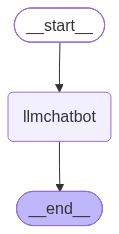

In [7]:
from IPython.display import Image,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [11]:
response = graph.invoke({"messages":"give me one line answer of who is the best cricketer in the world"})

In [12]:
response["messages"][-1].text

'Sir Donald Bradman is statistically considered the greatest cricketer of all time, while Sachin Tendulkar is widely regarded as the best of the modern era.'

In [9]:
from langchain_tavily import TavilySearch
tool = TavilySearch(max_results=2)
tools = [tool]
tool.invoke("Best Cricket Bowler in the world , one name answer just ")

{'query': 'Best Cricket Bowler in the world , one name answer just',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.youtube.com/watch?v=-PTNoumO-6g',
   'title': 'RANKED: Top 10 Test Bowlers THIS CENTURY! Warne, Murali, Bumrah AND MORE…',
   'content': "[38:33] Room for improvement. Yeah, room for growth there for Bumra. I mean, the guy with 800 test wickets is down at number six, but [laughter]\n[38:42] [gasps]\n[38:42] don't worry about that. So, Broady, go on, reveal it. Our best ever test bowler is, for the love of crickets, best test bowler of this century is a one and only Shane War.\n[38:52] Love that.\n[38:53] Has to be Shane War. What a bowl. [...] [16:49] Had some good fielders as well, didn't they? Unbelievable. Some good slip field. I saw something like Monage.\n[16:55] It was like 97% in test cricket because then because they just carry through to the slips you had like Smith callis\n[17:02] D. Not that that takes away from 

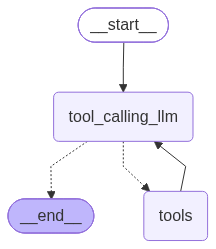

In [9]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode, tools_condition

llm_with_tools = llm.bind_tools(tools)

def tool_calling_llm(state:State):
    return {"messages" :[llm_with_tools.invoke(state["messages"])]}


builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")
graph = builder.compile()

from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))


In [15]:
response = graph.invoke({"messages":"Best Cricket wicketkeeper in the world , one name answer just "})

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


In [16]:
response["messages"][-1].text

'Adam Gilchrist'

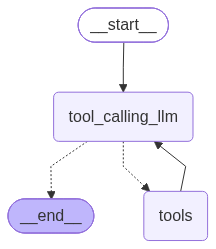

In [10]:
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

llm_with_tools = llm.bind_tools(tools)

def tool_calling_llm(state:State):
    return {"messages" :[llm_with_tools.invoke(state["messages"])]}


builder = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

builder.add_edge(START,"tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")
graph = builder.compile(checkpointer=memory)

from IPython.display import Image,display
display(Image(graph.get_graph().draw_mermaid_png()))

In [12]:
config = {"configurable":{"thread_id":"1"}}
response = graph.invoke({"messages":"Hi , My name is Syed Izzan Abbas"},config=config)
response

{'messages': [HumanMessage(content='Hi , My name is Syed Izzan Abbas', additional_kwargs={}, response_metadata={}, id='82ac0af6-0441-4d0d-b63c-7e492688a047'),
  AIMessage(content=[{'type': 'text', 'text': 'Hello Syed Izzan Abbas! Nice to meet you. How can I help you today?', 'extras': {'signature': 'EosCCogCAWkUfROqbCFst8smnK3vTVLF1m8s5Yb22XOQOkzgVzKtMiPUKdFBrIAgoyw9mSmSXacPQqW4oci1EXddKNvcjYyQu2HlBCs4yg+t4cx6uqM6amaru5CtBLAwhEnsgA3tBMTRwaVXUGiZ9lm3SXIQ6IDj1KY3tmFYxOwsZWXvZt/xLaYfWQpsBcFGL4buYY6tLHNS5gtYJ5P/WFoleNllUpiTO2LjCXTttnSyYbrE6mFnNJPsozU2pQVnGWefNz7fDCH6ivw+PELFSDudXBkY2G7TlX0srgiOdN0ZbpJJa9bpsDhSFArnL1r8Be/J/HzhBBA5AWJvaN3mfAPA1cH6ID8YPW7u6TFX'}}], additional_kwargs={}, response_metadata={'finish_reason': 'STOP', 'model_name': 'gemini-3.8-flash', 'safety_ratings': [], 'model_provider': 'google_genai'}, id='lc_run--01a16717-bc74-7c23-92ce-4179d9410035-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1501, 'output_tokens': 56, 'total_tokens': 1557, 'inp

In [13]:
response = graph.invoke({"messages":"Hey What is my name "},config= config)
print(response['messages'][-1].text)

Your name is **Syed Izzan Abbas**!
